# California Home Price Prediction
## Week 6: Feature Engineering

This notebook adds three simple ideas to the Week 5 feature set: property age, bedrooms per bathroom, and school-district location. The same Random Forest is used before and after so the comparison stays fair.

In [1]:
from pathlib import Path
import time
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.3f}".format

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "California"
DISTRICT_PATH = PROJECT_ROOT / "data" / "external" / "school_district_areas_2024_25.geojson"
RANDOM_STATE = 42

## 1. Load and clean the property data

Use the same source period, property filter, and target-quality rules as Week 5.

In [2]:
base_numeric = [
    "LivingArea", "BedroomsTotal", "BathroomsTotalInteger",
    "LotSizeSquareFeet", "YearBuilt", "Latitude", "Longitude",
    "GarageSpaces", "ParkingTotal"
]
base_categorical = [
    "City", "CountyOrParish", "PostalCode", "PoolPrivateYN",
    "ViewYN", "NewConstructionYN", "AttachedGarageYN"
]
columns = [
    "ListingKey", "CloseDate", "ClosePrice", "ListPrice",
    "PropertyType", "PropertySubType", *base_numeric, *base_categorical,
]

frames = []
for path in sorted(RAW_DIR.glob("CRMLSSold*.csv")):
    monthly = pd.read_csv(path, usecols=columns, low_memory=False)
    monthly["SourceMonth"] = int(path.stem[-6:])
    frames.append(monthly)
assert len(frames) == 15

raw_df = pd.concat(frames, ignore_index=True)
df = raw_df[
    raw_df["PropertyType"].eq("Residential")
    & raw_df["PropertySubType"].eq("SingleFamilyResidence")
].copy()

for column in ["ClosePrice", "ListPrice", *base_numeric]:
    df[column] = pd.to_numeric(df[column], errors="coerce")
df["CloseDate"] = pd.to_datetime(df["CloseDate"], errors="coerce")

close_to_list = df["ClosePrice"] / df["ListPrice"]
bad_target = (
    df["ClosePrice"].isna()
    | (df["ClosePrice"] < 10_000)
    | ((df["ListPrice"] > 0) & ~close_to_list.between(0.2, 5))
)
df = df.loc[~bad_target].copy()
df = df.sort_values(["CloseDate", "SourceMonth"]).drop_duplicates("ListingKey", keep="last")

invalid_rules = {
    "LivingArea": df["LivingArea"] <= 0,
    "BedroomsTotal": df["BedroomsTotal"] < 0,
    "BathroomsTotalInteger": df["BathroomsTotalInteger"] < 0,
    "LotSizeSquareFeet": df["LotSizeSquareFeet"] <= 0,
    "YearBuilt": (df["YearBuilt"] < 1800) | (df["YearBuilt"] > df["CloseDate"].dt.year),
    "Latitude": ~df["Latitude"].between(32, 42),
    "Longitude": ~df["Longitude"].between(-125, -114),
    "GarageSpaces": df["GarageSpaces"] < 0,
    "ParkingTotal": df["ParkingTotal"] < 0,
}
for column, mask in invalid_rules.items():
    df.loc[mask.fillna(False), column] = np.nan
for column in base_categorical:
    values = df[column].astype("string")
    df[column] = values.astype(object).where(values.notna(), np.nan)

print(f"Usable property sales: {len(df):,}")

Usable property sales: 161,082


## 2. Create two simple property features

- `PropertyAge`: age of the home when it sold.
- `BedroomsPerBathroom`: a simple measure of the home layout.

Invalid or undefined ratios stay missing and are handled by the model pipeline.

In [3]:
df["PropertyAge"] = df["CloseDate"].dt.year - df["YearBuilt"]
df["BedroomsPerBathroom"] = (
    df["BedroomsTotal"] / df["BathroomsTotalInteger"].replace(0, np.nan)
)
df[["PropertyAge", "BedroomsPerBathroom"]].describe().T

,count,mean,std,min,25%,50%,75%,max
PropertyAge,"160,961.000",49.399,27.624,0.000,27.000,49.000,70.000,225.000
BedroomsPerBathroom,"160,985.000",1.454,0.473,0.000,1.000,1.500,1.500,7.500


## 3. Add the school-district layer

Convert property coordinates into map points and spatially join them to the official California School District Areas 2024–25 boundaries.

The boundary file contains overlapping Elementary, High, and Unified layers. To keep the output clear, create one primary and one secondary district field.

In [4]:
districts = gpd.read_file(DISTRICT_PATH)[
    ["DistrictName", "DistrictType", "geometry"]
].to_crs("EPSG:4326")

valid_coordinates = df["Latitude"].notna() & df["Longitude"].notna()
points = gpd.GeoDataFrame(
    df.loc[valid_coordinates, ["ListingKey"]].copy(),
    geometry=gpd.points_from_xy(
        df.loc[valid_coordinates, "Longitude"],
        df.loc[valid_coordinates, "Latitude"],
    ),
    crs="EPSG:4326",
)

def district_lookup(district_types):
    selected = districts[districts["DistrictType"].isin(district_types)]
    joined = gpd.sjoin(
        points,
        selected[["DistrictName", "geometry"]],
        how="left",
        predicate="within",
    )
    return joined.groupby("ListingKey")["DistrictName"].agg(
        lambda values: " / ".join(sorted(set(values.dropna()))) or np.nan
    )

primary_lookup = district_lookup(["Elementary", "Unified"])
secondary_lookup = district_lookup(["High", "Unified"])
df["PrimarySchoolDistrict"] = df["ListingKey"].map(primary_lookup)
df["SecondarySchoolDistrict"] = df["ListingKey"].map(secondary_lookup)

district_summary = pd.DataFrame({
    "feature": ["PrimarySchoolDistrict", "SecondarySchoolDistrict"],
    "coverage_percent": [
        df["PrimarySchoolDistrict"].notna().mean() * 100,
        df["SecondarySchoolDistrict"].notna().mean() * 100,
    ],
    "unique_values": [
        df["PrimarySchoolDistrict"].nunique(),
        df["SecondarySchoolDistrict"].nunique(),
    ],
})
display(district_summary)

,feature,coverage_percent,unique_values
0,PrimarySchoolDistrict,99.950,684
1,SecondarySchoolDistrict,99.876,394


## 4. Build simple feature groups

Test the property and school-district features separately on March validation. This avoids keeping features only because they are new.

In [5]:
engineered_numeric = ["PropertyAge", "BedroomsPerBathroom"]
engineered_categorical = ["PrimarySchoolDistrict", "SecondarySchoolDistrict"]

week5_features = base_numeric + base_categorical
week6_numeric = base_numeric + engineered_numeric
week6_categorical = base_categorical + engineered_categorical
week6_features = week6_numeric + week6_categorical
target = "ClosePrice"

development_train = df[df["SourceMonth"].between(202504, 202602)].copy()
validation = df[df["SourceMonth"] == 202603].copy()
train = df[df["SourceMonth"].between(202504, 202603)].copy()
test = df[df["SourceMonth"] == 202604].copy()
assert set(development_train["ListingKey"]).isdisjoint(set(validation["ListingKey"]))
assert set(train["ListingKey"]).isdisjoint(set(test["ListingKey"]))

def make_pipeline(numeric_features, categorical_features, n_estimators, min_samples_leaf=3):
    preprocessor = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ]), numeric_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("onehot", OneHotEncoder(
                handle_unknown="infrequent_if_exist", min_frequency=10
            )),
        ]), categorical_features),
    ])
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=n_estimators, min_samples_leaf=min_samples_leaf, max_features=0.7,
            n_jobs=-1, random_state=RANDOM_STATE,
        )),
    ])

feature_sets = {
    "Week 5 base": (base_numeric, base_categorical),
    "Property features only": (base_numeric + engineered_numeric, base_categorical),
    "School districts only": (base_numeric, base_categorical + engineered_categorical),
    "All Week 6 features": (week6_numeric, week6_categorical),
}

## 5. Select features with March validation

Use a smaller forest for a quick, fair feature screen. Select by validation R² because it is the main project metric. April remains untouched.

In [6]:
validation_rows = []

for name, (numeric_set, categorical_set) in feature_sets.items():
    selected_features = numeric_set + categorical_set
    model = make_pipeline(numeric_set, categorical_set, n_estimators=20)
    model.fit(development_train[selected_features], development_train[target])
    predicted = model.predict(validation[selected_features])
    validation_rows.append({
        "feature_set": name,
        "validation_r2": r2_score(validation[target], predicted),
        "validation_mae": mean_absolute_error(validation[target], predicted),
    })

validation_results = pd.DataFrame(validation_rows).sort_values(
    "validation_r2", ascending=False
).reset_index(drop=True)
display(validation_results)
print(f"Selected: {validation_results.loc[0, 'feature_set']}")

,feature_set,validation_r2,validation_mae
0,Property features only,0.799,"200,551.681"
1,Week 5 base,0.786,"200,214.959"
2,School districts only,0.784,"199,233.161"
3,All Week 6 features,0.783,"202,194.012"


Selected: Property features only


## 6. Check one small model change

The new features did not improve both validation metrics. Keep the simpler base set and compare only two leaf sizes. A smaller leaf lets the forest learn more local price patterns.

In [7]:
architecture_rows = []
for leaf_size in [3, 1]:
    model = make_pipeline(
        base_numeric, base_categorical,
        n_estimators=20, min_samples_leaf=leaf_size,
    )
    model.fit(development_train[week5_features], development_train[target])
    predicted = model.predict(validation[week5_features])
    architecture_rows.append({
        "min_samples_leaf": leaf_size,
        "validation_r2": r2_score(validation[target], predicted),
        "validation_mae": mean_absolute_error(validation[target], predicted),
    })

architecture_results = pd.DataFrame(architecture_rows)
display(architecture_results)

,min_samples_leaf,validation_r2,validation_mae
0,3,0.786,"200,214.959"
1,1,0.818,"195,346.918"


## 7. Final April comparison

Refit the reference and optimized forests on all 12 training months. Both use the simpler Week 5 feature set.

In [8]:
final_models = {
    "Reference forest (leaf=3)": 3,
    "Optimized forest (leaf=1)": 1,
}

results = []
models = {}
for name, leaf_size in final_models.items():
    model = make_pipeline(
        base_numeric, base_categorical,
        n_estimators=100, min_samples_leaf=leaf_size,
    )
    start = time.perf_counter()
    model.fit(train[week5_features], train[target])
    predicted = model.predict(test[week5_features])
    models[name] = model
    results.append({
        "feature_set": name,
        "test_r2": r2_score(test[target], predicted),
        "test_mae": mean_absolute_error(test[target], predicted),
        "test_rmse": mean_squared_error(test[target], predicted) ** 0.5,
        "fit_seconds": time.perf_counter() - start,
    })

results = pd.DataFrame(results)
display(results)

r2_gain = results.loc[1, "test_r2"] - results.loc[0, "test_r2"]
mae_change = results.loc[1, "test_mae"] - results.loc[0, "test_mae"]
print(f"R² change: {r2_gain:+.3f}")
print(f"MAE change: ${mae_change:+,.0f}")

,feature_set,test_r2,test_mae,test_rmse,fit_seconds
0,Reference forest (leaf=3),0.762,"207,343.446","770,531.080",252.038
1,Optimized forest (leaf=1),0.767,"204,349.954","762,596.108",346.942


R² change: +0.005
MAE change: $-2,993


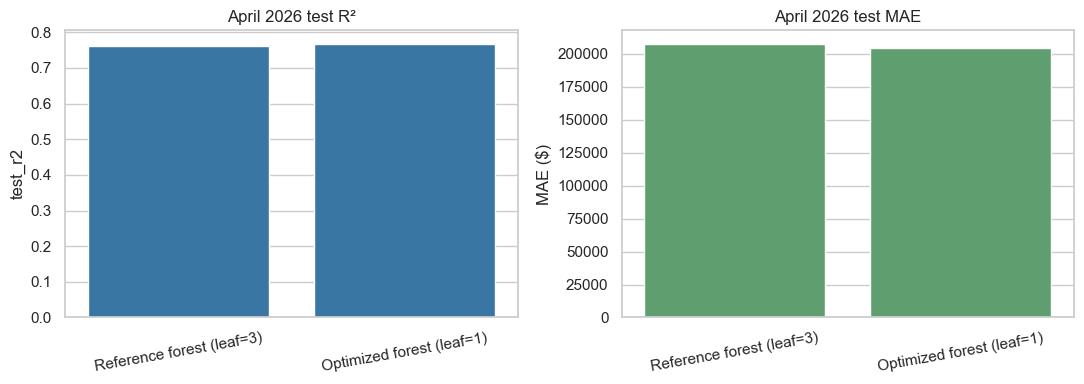

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=results, x="feature_set", y="test_r2", color="#2878B5", ax=axes[0])
axes[0].set_title("April 2026 test R²")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=10)
sns.barplot(data=results, x="feature_set", y="test_mae", color="#55A868", ax=axes[1])
axes[1].set_title("April 2026 test MAE")
axes[1].set_xlabel("")
axes[1].set_ylabel("MAE ($)")
axes[1].tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()

## 8. Review the optimized model

Combine one-hot columns back into their original feature names so the result is easy to interpret.

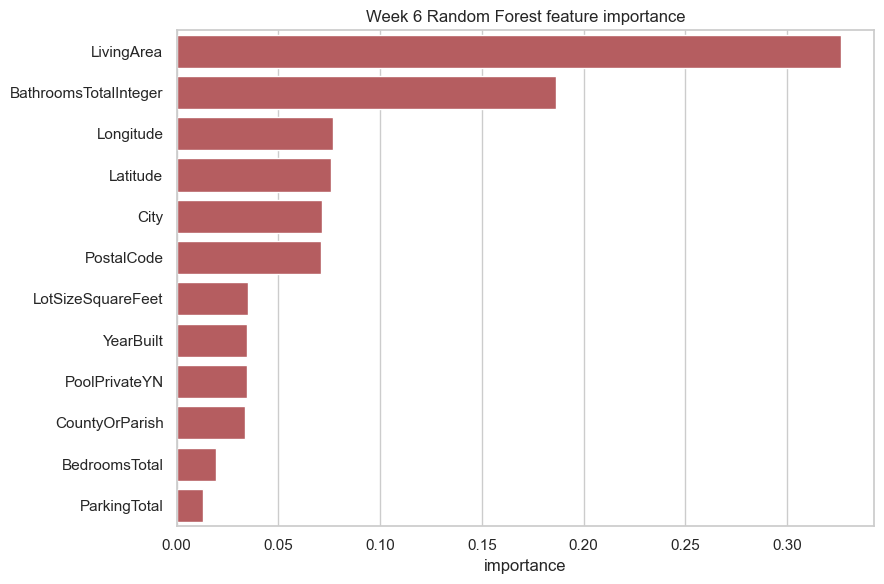

,feature,importance
7,LivingArea,0.326
1,BathroomsTotalInteger,0.187
8,Longitude,0.077
6,Latitude,0.076
3,City,0.071
13,PostalCode,0.071
9,LotSizeSquareFeet,0.035
15,YearBuilt,0.035
12,PoolPrivateYN,0.035
4,CountyOrParish,0.033


In [10]:
week6_model = models["Optimized forest (leaf=1)"]
encoded_names = week6_model.named_steps["preprocessor"].get_feature_names_out()
encoded_importance = pd.DataFrame({
    "encoded_feature": encoded_names,
    "importance": week6_model.named_steps["model"].feature_importances_,
})

selected_features = week5_features

def original_feature(encoded_name):
    for feature in selected_features:
        if feature in encoded_name:
            return feature
    return encoded_name

encoded_importance["feature"] = encoded_importance["encoded_feature"].map(original_feature)
importance = (encoded_importance.groupby("feature", as_index=False)["importance"]
              .sum().sort_values("importance", ascending=False))

plt.figure(figsize=(9, 6))
sns.barplot(data=importance.head(12), x="importance", y="feature", color="#C44E52")
plt.title("Week 6 Random Forest feature importance")
plt.ylabel("")
plt.tight_layout()
plt.show()
display(importance.head(12))

## Conclusion

- Added two simple property features and two school-district fields.
- School districts came from a coordinate-based spatial join with the official 2024–25 boundaries.
- Used March validation to test feature groups and one small architecture change.
- The new features did not consistently improve performance, so the simpler Week 5 feature set was retained.
- Reducing `min_samples_leaf` from 3 to 1 improved the final Random Forest without adding more features.

The next step is Week 7 advanced models and light hyperparameter tuning.